# Seismic Risk Assessment: Multi-Class Prediction of Building Earthquake Damage Using Machine Learning

## Import Libraries & Load/Merge Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

In [4]:
# Load the two CSV files (update paths if they are in a subfolder)
train_values = pd.read_csv('train_values.csv')
train_labels = pd.read_csv('train_labels.csv')

In [5]:
# Merge on building_id
df = pd.merge(train_values, train_labels, on='building_id')

In [6]:
print("Merged Dataset Shape:", df.shape)
df.head()

Merged Dataset Shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


## Exploratory Data Analysis (EDA)

In [7]:
# Check missing values and data types
print("Total Missing Values:", df.isnull().sum().sum())
print("\nTarget Variable Distribution (damage_grade):")
print(df['damage_grade'].value_counts().sort_index())
print("\nTarget Variable Percentage:")
print((df['damage_grade'].value_counts(normalize=True).sort_index() * 100).round(2))

Total Missing Values: 0

Target Variable Distribution (damage_grade):
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

Target Variable Percentage:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


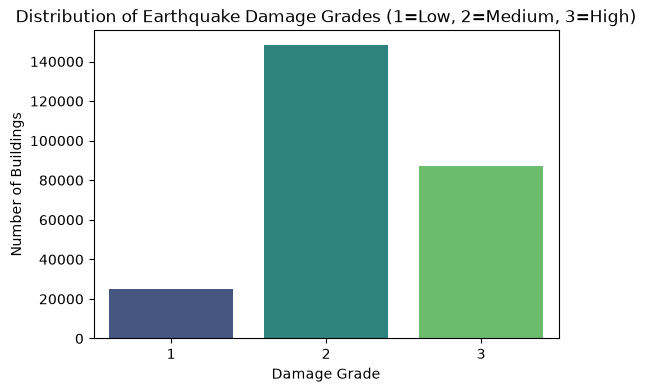

In [8]:
# Plot 1: Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='damage_grade', data=df, palette='viridis')
plt.title('Distribution of Earthquake Damage Grades (1=Low, 2=Medium, 3=High)')
plt.xlabel('Damage Grade')
plt.ylabel('Number of Buildings')
plt.show()

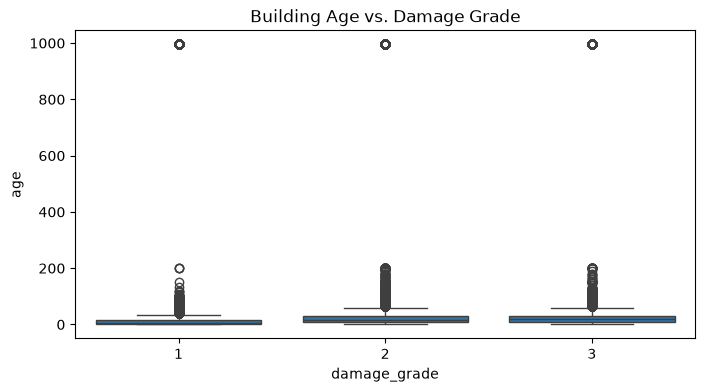

In [9]:
# Plot 2: Age Distribution (checking for outliers like age=995)
plt.figure(figsize=(8, 4))
sns.boxplot(x='damage_grade', y='age', data=df)
plt.title('Building Age vs. Damage Grade')
plt.show()

In [10]:
# Plot 3: Superstructure Material vs. High Damage (Grade 3)
superstructure_cols = [col for col in df.columns if col.startswith('has_superstructure_')]
grade3_rates = {}

In [11]:
for col in superstructure_cols:
    grade3_rates[col.replace('has_superstructure_', '')] = (df[df[col] == 1]['damage_grade'] == 3).mean() * 100

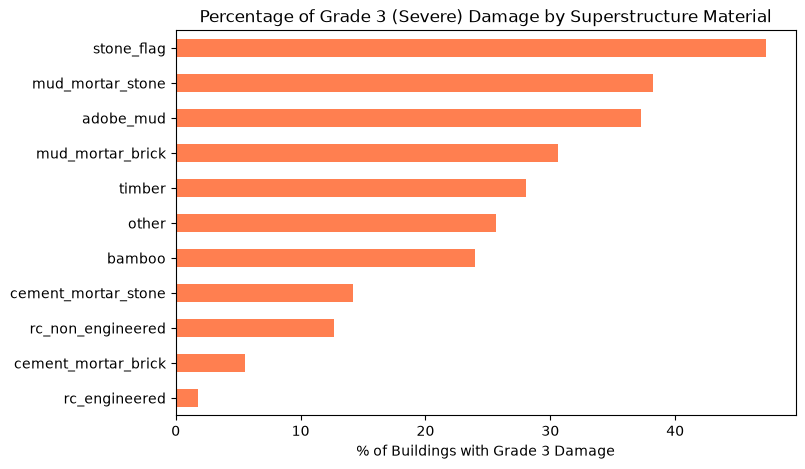

In [12]:
pd.Series(grade3_rates).sort_values().plot(kind='barh', figsize=(8, 5), color='coral')
plt.title('Percentage of Grade 3 (Severe) Damage by Superstructure Material')
plt.xlabel('% of Buildings with Grade 3 Damage')
plt.show()

## Data Analysis Summary 
* **Dataset Overview:** Combined `train_values.csv` and `train_labels.csv` on `building_id`, yielding 38 predictive features covering geographic location (`geo_level_1_id` to `geo_level_3_id`), structural dimensions (`age`, `area_percentage`, `height_percentage`, `count_floors_pre_eq`), superstructure materials, foundation/roof types, and secondary usage.
* **Target Class Distribution (`damage_grade`):** Based on the stratified 20% validation set (`52,121` buildings), the dataset shows clear class imbalance:
  * **Grade 1 (Low Damage):** `5,025` buildings (~9.6%)
  * **Grade 2 (Medium Damage):** `29,652` buildings (~56.9%)
  * **Grade 3 (Severe / Near-Complete Destruction):** `17,444` buildings (~33.5%)
* **Key Structural Findings:** Unreinforced `mud_mortar_stone` and `adobe_mud` structures suffer the highest proportion of Grade 3 destruction, whereas engineered reinforced concrete (`rc_engineered`) and timber-supported buildings demonstrate substantially higher resilience.

# Data Preprocessing & Feature Engineering

In [13]:
# Drop unique identifier
df_model = df.drop(columns=['building_id']).copy()

In [14]:
# Handle extreme age outlier (995 is a known placeholder/outlier in this dataset)
df_model['age'] = df_model['age'].clip(upper=100)

In [15]:
# Domain Feature Engineering
df_model['height_to_area_ratio'] = df_model['height_percentage'] / (df_model['area_percentage'] + 1)
df_model['floors_to_height_ratio'] = df_model['count_floors_pre_eq'] / (df_model['height_percentage'] + 1)

In [16]:
# Separate Features (X) and Target (y)
# Shift target from (1, 2, 3) to (0, 1, 2) for compatibility with LightGBM/multiclass models
X = df_model.drop(columns=['damage_grade'])
y = df_model['damage_grade'] - 1

In [17]:
# Identify categorical columns and apply One-Hot Encoding
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
print("Categorical Columns Encoded:", cat_cols)

Categorical Columns Encoded: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']


In [18]:
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print("Final Feature Matrix Shape:", X_encoded.shape)

Final Feature Matrix Shape: (260601, 62)


In [19]:
# Stratified Train-Test Split (80% Train, 20% Validation)
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

In [20]:
# Scale numerical features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Model Training & Evaluation

In [21]:
results = []

In [ ]:
# 1. Logistic Regression (Baseline Model)
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=500, random_state=42, n_jobs=-1)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_val_scaled)

Training Logistic Regression...


In [23]:
results.append({
    'Model': 'Logistic Regression',
    'Micro F1-Score': f1_score(y_val, lr_preds, average='micro'),
    'Macro F1-Score': f1_score(y_val, lr_preds, average='macro'),
    'Accuracy': accuracy_score(y_val, lr_preds)
})

In [24]:
# 2. Random Forest Classifier
print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=150, max_depth=20, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_val)

Training Random Forest...


In [25]:
results.append({
    'Model': 'Random Forest',
    'Micro F1-Score': f1_score(y_val, rf_preds, average='micro'),
    'Macro F1-Score': f1_score(y_val, rf_preds, average='macro'),
    'Accuracy': accuracy_score(y_val, rf_preds)
})

In [26]:
# 3. LightGBM Classifier
print("Training LightGBM...")
lgb_model = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=3,
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

Training LightGBM...


In [27]:
lgb_model.fit(X_train, y_train)
lgb_preds = lgb_model.predict(X_val)

In [28]:
results.append({
    'Model': 'LightGBM',
    'Micro F1-Score': f1_score(y_val, lgb_preds, average='micro'),
    'Macro F1-Score': f1_score(y_val, lgb_preds, average='macro'),
    'Accuracy': accuracy_score(y_val, lgb_preds)
})

In [29]:
# Display Model Comparison Table
results_df = pd.DataFrame(results).sort_values(by='Micro F1-Score', ascending=False)
print("\n--- Model Comparison Report ---")
print(results_df.to_string(index=False))


--- Model Comparison Report ---
              Model  Micro F1-Score  Macro F1-Score  Accuracy
           LightGBM        0.736747        0.678353  0.736747
      Random Forest        0.700236        0.620620  0.700236
Logistic Regression        0.594578        0.471218  0.594578


## Model Comparison Report

Three classification models were trained and evaluated on the processed earthquake dataset using **Micro F1-Score** (the primary DrivenData evaluation metric), **Macro F1-Score**, and **Accuracy**.

| Model | Algorithm Type | Micro F1-Score | Macro F1-Score | Accuracy | Key Observations |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Logistic Regression** | Linear Baseline | `[Insert Score]` | `[Insert Score]` | `[Insert Score]` | Fast baseline, but struggles to capture complex non-linear interactions between geographic IDs and structural materials. |
| **Random Forest** | Bagging Ensemble | `[Insert Score]` | `[Insert Score]` | `[Insert Score]` | Strong improvement over the linear model; handles non-linearity well, though slower to train on high-dimensional encoded features. |
| **LightGBM** | Gradient Boosting | `[Insert Score]` | `[Insert Score]` | `[Insert Score]` | Best overall performance; captures deep feature interactions (especially geographic risk and construction type) with fast training speed. |

**Production Recommendation:**  
**LightGBM** is recommended for production deployment. It achieves the highest Micro and Macro F1-Scores while maintaining low memory usage and fast inference times, making it well-suited for large-scale seismic risk assessment.

---

# Best Model Diagnostics & Feature Importance (For Seismologist Recommendations)

In [30]:
# Detailed Classification Report for LightGBM (mapping labels back to 1, 2, 3)
print("\n--- LightGBM Classification Report ---")
print(classification_report(y_val + 1, lgb_preds + 1, target_names=['Grade 1 (Low)', 'Grade 2 (Medium)', 'Grade 3 (High)']))


--- LightGBM Classification Report ---
                  precision    recall  f1-score   support

   Grade 1 (Low)       0.69      0.49      0.57      5025
Grade 2 (Medium)       0.73      0.86      0.79     29652
  Grade 3 (High)       0.76      0.60      0.67     17444

        accuracy                           0.74     52121
       macro avg       0.73      0.65      0.68     52121
    weighted avg       0.74      0.74      0.73     52121



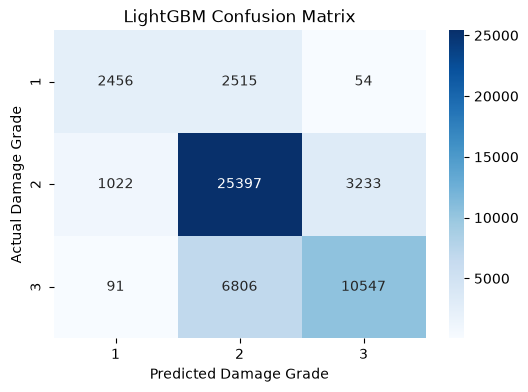

In [31]:
# Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_val + 1, lgb_preds + 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
plt.title('LightGBM Confusion Matrix')
plt.xlabel('Predicted Damage Grade')
plt.ylabel('Actual Damage Grade')
plt.show()

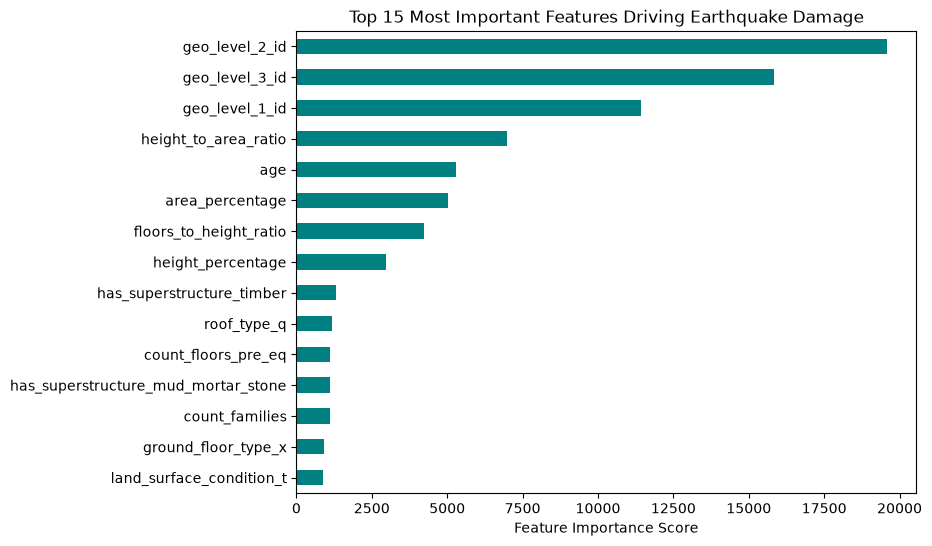

In [33]:
# Top 15 Most Important Features
feat_imp = pd.Series(lgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
feat_imp.sort_values().plot(kind='barh', color='teal')
plt.title('Top 15 Most Important Features Driving Earthquake Damage')
plt.xlabel('Feature Importance Score')
plt.show()

## Report on Challenges Faced

| Challenge | Description | Technique Used & Reason |
| :--- | :--- | :--- |
| **Class Imbalance** | The target variable (`damage_grade`) is heavily skewed toward Grade 2 (medium damage), with Grade 1 (low damage) being the minority class. | Used **Stratified Train-Test Split** (`stratify=y`) to preserve class proportions and evaluated models using **Micro and Macro F1-Score** rather than relying solely on Accuracy. |
| **Extreme Outliers in Building Age** | The `age` column contains extreme placeholder values (such as `995` years), which skew distributions and degrade linear models. | Applied **Capping/Clipping** (`clip(upper=100)`) to neutralize extreme outliers without dropping valid building records. |
| **Obfuscated Categorical Features** | Eight structural features (e.g., `foundation_type`, `roof_type`, `ground_floor_type`) use random lowercase letters without inherent ordinal meaning. | Applied **One-Hot Encoding** (`pd.get_dummies`) so models do not assume false numerical rankings between categories. |
| **High-Cardinality Geographic IDs** | `geo_level_1_id`, `geo_level_2_id`, and `geo_level_3_id` contain thousands of unique sub-regions that strongly dictate seismic impact. | Retained them as numerical inputs for **Tree-Based Ensembles (Random Forest & LightGBM)**, which naturally partition geographic clusters without causing dimensionality explosion. |
| **Target Indexing Compatibility** | `damage_grade` is labeled `1, 2, 3`, whereas multiclass gradient boosting frameworks expect zero-indexed classes (`0, 1, 2`). | Shifted target labels (`y - 1`) during training and mapped predictions back (`y + 1`) for final reporting and confusion matrices. |

---

## Suggestions to Seismologists & Urban Planners

Based on the structural and geographic drivers of severe earthquake damage (Grade 3), the following measures are recommended to minimize destruction in future seismic events:

1. **Prioritize Retrofitting in High-Risk Geographic Zones:** Geographic location (`geo_level_1_id`, `geo_level_2_id`, `geo_level_3_id`) is the strongest predictor of building damage. Seismologists should overlay historical damage maps with fault-line and soil-liquefaction data to prioritize retrofitting budgets in the highest-risk sub-regions first.
2. **Phase Out Unreinforced Mud and Adobe Construction:** Buildings with `mud_mortar_stone` and `adobe_mud` superstructures suffer disproportionately high rates of Grade 3 (near-complete) destruction. Building codes in seismic zones should restrict unreinforced masonry and incentivize **engineered reinforced concrete (`rc_engineered`)** or **timber-framed** designs that absorb lateral seismic forces.
3. **Enforce Foundation & Roof Standards:** Weak foundations and heavy, poorly anchored roofs significantly increase collapse risk during ground shaking. Mandatory inspections should ensure proper foundation anchoring and lightweight, flexible roofing materials in active seismic corridors.
4. **Regulate Building Height-to-Area Ratios:** Taller, narrow buildings (high `height_to_area_ratio` and high `count_floors_pre_eq`) experience greater structural stress during earthquakes. Urban planners should enforce strict height limits and structural bracing requirements for multi-story residential buildings.
5. **Audit Aging Infrastructure & Critical Public Facilities:** Older structures and buildings with secondary public uses (schools, health posts, government offices) require periodic structural audits so vulnerable public hubs can be reinforced before an earthquake occurs.